# Agentic RAG 단기 기억(Short-term Memory) 실습 — 수동 구현

— PostgreSQL(`ragdb`)에 대화 기록 저장하고 조회하기

LangGraph의 `StateGraph`는 `invoke()` 한 번이 끝나면 State가 사라진다.
**여러 번의 질문-답변을 같은 대화로 이어가려면(단기 기억)** 이전 대화를 어딘가에 저장해두고,
다음 질문을 처리할 때 다시 불러와야 한다. 이 노트북에서는 그 저장소로 **PostgreSQL 테이블을 직접 만들어** 쓴다.

| 기억 종류 | 범위 | 이 실습에서는 |
|---|---|---|
| 단기 기억(Short-term) | 같은 세션(대화) 안에서 바로 이전 턴을 기억 | `chat_history` 테이블의 `session_id`로 구현 |
| 장기 기억(Long-term) | 세션을 넘어 영구적으로 남는 지식/선호 | 다루지 않음 |

> 사전 조건: PostgreSQL 실행 중(`cd docker-postgresql && docker compose up -d`) + Qdrant 실행 중(`cd docker-qdrant && docker compose up -d`) + 색인 완료(`uv run python -m rag.indexer`)

> 같은 시나리오를 LangGraph 내장 체크포인터(`PostgresSaver`)로 구현한 버전은 [`2-2.short_term_memory_checkpointer.ipynb`](2-2.short_term_memory_checkpointer.ipynb)에 있다. 두 노트북은 서로 **독립적으로** 실행할 수 있다.


## 0. 환경 설정


In [1]:
from typing import TypedDict

from IPython.display import Image, Markdown, display
from langchain_core.caches import InMemoryCache
from langchain_core.globals import set_llm_cache
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import END, START, StateGraph

from common.ai_model import get_llm_model
from common.config import RERANK_TOP_N, RETRIEVAL_TOP_K
from common.postgres import get_postgres_connection
from rag.chunker import format_article_label
from rag.reranker import rerank
from rag.retriever import RetrievedChunk, retrieve


In [2]:
# 동일 질문 반복 호출 시 토큰 비용을 아끼기 위한 인메모리 LLM 캐시
# (프로세스 내 캐시이므로 노트북 재시작 시 초기화됨)
set_llm_cache(InMemoryCache())

# 답변 생성용 LLM
answer_llm = get_llm_model(max_tokens=1024)


### 공통 헬퍼 (`1.agentic_rag.ipynb`의 Step 1과 동일)

- `search_law`: Hybrid 검색(Dense+BM25, RRF) → LLM Rerank
- `format_context` / `format_sources`: 검색 결과를 LLM 입력용 / 출력용 문자열로 변환
- `show_graph`: 그래프 구조 시각화


In [3]:
def search_law(query: str) -> list[RetrievedChunk]:
    """rag 모듈로 Hybrid 검색 후 Rerank해 상위 N개 조문을 반환한다."""
    candidates = retrieve(query, top_k=RETRIEVAL_TOP_K, use_hybrid=True)
    return rerank(query, candidates, top_n=RERANK_TOP_N)


def format_context(documents: list[RetrievedChunk]) -> str:
    """검색된 조문 텍스트를 LLM context 문자열로 합친다."""
    return "\n\n".join(doc.chunk.text for doc in documents)


def format_sources(documents: list[RetrievedChunk]) -> str:
    """검색된 조문을 '제N조(제목)' 목록 문자열로 만든다."""
    labels = []
    for doc in documents:
        label = format_article_label(doc.chunk.article_no)
        title = f"({doc.chunk.article_title})" if doc.chunk.article_title else ""
        labels.append(f"{label}{title}")
    return ", ".join(dict.fromkeys(labels)) or "(없음)"


def show_graph(graph) -> None:
    """그래프 구조를 PNG로 표시하고, 실패하면 Mermaid 텍스트로 출력한다."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())


---
## 1. PostgreSQL에 대화 기록 테이블 만들기

대화 메시지 1건을 1행으로 저장한다. 같은 대화(세션)인지는 `session_id` 컬럼으로 구분한다.

| 컬럼 | 의미 |
|---|---|
| `id` | 자동 증가 기본키 |
| `session_id` | 대화(세션)를 구분하는 값 |
| `role` | `'user'`(사용자 질문) 또는 `'assistant'`(AI 답변) |
| `content` | 메시지 내용 |
| `created_at` | 저장 시각 (대화 순서를 가리기 위해 사용) |


In [4]:
CREATE_TABLE_SQL = """
CREATE TABLE IF NOT EXISTS chat_history (
    id SERIAL PRIMARY KEY,
    session_id TEXT NOT NULL,
    role TEXT NOT NULL,
    content TEXT NOT NULL,
    created_at TIMESTAMP NOT NULL DEFAULT NOW()
);
"""


def create_chat_history_table() -> None:
    """chat_history 테이블이 없으면 새로 만든다."""
    conn = get_postgres_connection()
    try:
        with conn.cursor() as cur:
            cur.execute(CREATE_TABLE_SQL)
        conn.commit()
    finally:
        conn.close()


create_chat_history_table()
print("chat_history 테이블 준비 완료")


chat_history 테이블 준비 완료


---
## 2. 메시지 저장(`save_message`) / 조회(`load_recent_messages`) 함수

- `save_message`: 메시지 1건을 테이블에 `INSERT`
- `load_recent_messages`: 같은 `session_id`의 최근 N건을 **오래된 순서**로 불러옴 (최신순으로 `LIMIT`한 뒤 다시 뒤집어서, '최근 N건을 시간순으로' 만든다)


In [5]:
def save_message(session_id: str, role: str, content: str) -> None:
    """대화 메시지 1건을 chat_history 테이블에 저장한다."""
    conn = get_postgres_connection()
    try:
        with conn.cursor() as cur:
            cur.execute(
                "INSERT INTO chat_history (session_id, role, content) VALUES (%s, %s, %s)",
                (session_id, role, content),
            )
        conn.commit()
    finally:
        conn.close()


def load_recent_messages(session_id: str, limit: int = 6) -> list[dict]:
    """같은 session_id의 최근 메시지를 오래된 순으로 limit건 불러온다."""
    conn = get_postgres_connection()
    try:
        with conn.cursor() as cur:
            cur.execute(
                """
                SELECT role, content FROM chat_history
                WHERE session_id = %s
                ORDER BY created_at DESC
                LIMIT %s
                """,
                (session_id, limit),
            )
            rows = cur.fetchall()
    finally:
        conn.close()
    rows.reverse()  # 최신순으로 가져왔으므로 다시 오래된순으로 뒤집는다
    return [{"role": role, "content": content} for role, content in rows]


### 단독 테스트 — 그래프 없이 저장/조회 함수만 확인


In [6]:
TEST_SESSION = "test-session"

save_message(TEST_SESSION, "user", "안녕하세요")
save_message(TEST_SESSION, "assistant", "안녕하세요! 무엇을 도와드릴까요?")

for turn in load_recent_messages(TEST_SESSION):
    print(turn["role"], "→", turn["content"])


user → 안녕하세요
assistant → 안녕하세요! 무엇을 도와드릴까요?
user → 안녕하세요
assistant → 안녕하세요! 무엇을 도와드릴까요?
user → 안녕하세요
assistant → 안녕하세요! 무엇을 도와드릴까요?


---
## 3. LangGraph에 연결하기

`1.agentic_rag.ipynb` Step 1(`retrieve → generate`) 그래프에 **기억을 불러오는 노드**와 **기억을 저장하는 노드**를 앞뒤로 붙인다.

```
START → load_memory → retrieve → generate → save_memory → END
```

- `load_memory`: DB에서 이전 대화를 불러와 State에 담는다
- `generate`: 이전 대화(`history`) + 검색된 조문(`documents`)을 함께 참고해 답변한다
- `save_memory`: 이번 턴의 질문과 답변을 DB에 저장해, 다음 턴에서 불러올 수 있게 한다


In [7]:
class MemoryState(TypedDict):
    session_id: str                 # 대화를 구분하는 키 (같으면 같은 대화로 취급)
    question: str                   # 이번 턴의 사용자 질문
    history: list[dict]             # DB에서 불러온 이전 대화 (role, content)
    documents: list[RetrievedChunk]
    answer: str


In [8]:
def load_memory_node(state: MemoryState) -> dict:
    history = load_recent_messages(state["session_id"])
    print(f"  [load_memory] 이전 대화 {len(history)}건 불러옴")
    return {"history": history}


def memory_retrieve_node(state: MemoryState) -> dict:
    return {"documents": search_law(state["question"])}


def format_history(history: list[dict]) -> str:
    """이전 대화 기록을 '사용자: ...' / 'AI: ...' 줄글로 만든다."""
    if not history:
        return "(이전 대화 없음)"
    lines = []
    for turn in history:
        speaker = "사용자" if turn["role"] == "user" else "AI"
        lines.append(f"{speaker}: {turn['content']}")
    return "\n".join(lines)


MEMORY_ANSWER_SYSTEM_PROMPT = (
    "너는 인공지능기본법 QA 어시스턴트다. <history>의 이전 대화 흐름을 참고해 "
    "이번 질문의 의도(지시어가 가리키는 대상 등)를 파악하라. "
    "답변은 반드시 <context>의 조문만 근거로 하고, 근거 조문(예: 제2조)을 끝에 명시하라. "
    "context에 없는 내용은 모른다고 답하라."
)


def memory_generate_node(state: MemoryState) -> dict:
    context = format_context(state["documents"])
    history_text = format_history(state["history"])
    response = answer_llm.invoke([
        SystemMessage(content=MEMORY_ANSWER_SYSTEM_PROMPT),
        HumanMessage(
            content=(
                f"<history>\n{history_text}\n</history>\n\n"
                f"질문: {state['question']}\n\n"
                f"<context>\n{context}\n</context>"
            )
        ),
    ])
    return {"answer": response.content}


def save_memory_node(state: MemoryState) -> dict:
    save_message(state["session_id"], "user", state["question"])
    save_message(state["session_id"], "assistant", state["answer"])
    print("  [save_memory] 이번 질문/답변 저장 완료")
    return {}


### 그래프 조립


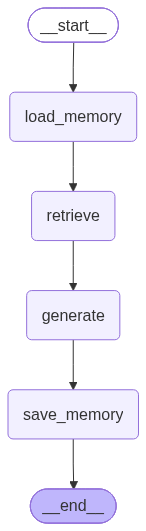

In [9]:
builder = StateGraph(MemoryState)
builder.add_node("load_memory", load_memory_node)
builder.add_node("retrieve", memory_retrieve_node)
builder.add_node("generate", memory_generate_node)
builder.add_node("save_memory", save_memory_node)

builder.add_edge(START, "load_memory")
builder.add_edge("load_memory", "retrieve")
builder.add_edge("retrieve", "generate")
builder.add_edge("generate", "save_memory")
builder.add_edge("save_memory", END)

memory_graph = builder.compile()
show_graph(memory_graph)


---
## 4. 실행 — 같은 세션은 기억하고, 다른 세션은 기억하지 못하는지 확인


In [10]:
def run_memory(graph, session_id: str, question: str) -> dict:
    """그래프를 실행하고 근거 조문ㆍ답변을 출력한 뒤 최종 State를 반환한다."""
    print(f"[{session_id}] Q. {question}")
    result = graph.invoke({"session_id": session_id, "question": question})
    print("근거 조문:", format_sources(result["documents"]))
    display(Markdown(result["answer"]))
    return result


**① 첫 질문** — `SESSION_A`로 '고영향 인공지능'에 대해 묻는다. 이전 대화가 없으므로 `load_memory`가 0건을 불러온다.


In [12]:
SESSION_A = "demo-session-1"

_ = run_memory(
    memory_graph,
    SESSION_A,
    "고영향 인공지능이란 무엇인가요?"
)


[demo-session-1] Q. 고영향 인공지능이란 무엇인가요?
  [load_memory] 이전 대화 4건 불러옴
  [save_memory] 이번 질문/답변 저장 완료
근거 조문: 제제1조조(목적)


제공된 <context>에는 **“고영향 인공지능”의 정의**가 없습니다. 따라서 무엇인지 **알 수 없습니다**.

근거: **제1조**

**② 후속 질문(같은 세션)** — '그것'이라는 지시어로 직전 답변을 가리킨다. `load_memory`가 ①의 대화를 불러오므로, AI가 '그것 = 고영향 인공지능'임을 이해할 수 있어야 한다.


In [13]:
_ = run_memory(memory_graph, SESSION_A, "그것을 만든 사업자는 어떤 책무를 지나요?")


[demo-session-1] Q. 그것을 만든 사업자는 어떤 책무를 지나요?
  [load_memory] 이전 대화 6건 불러옴
  [save_memory] 이번 질문/답변 저장 완료
근거 조문: 제제1조조(목적)


제공된 `<context>`에는 **인공지능을 만든 사업자의 책무**에 관한 내용이 없습니다. 따라서 **알 수 없습니다**.

근거: **제1조**

**③ 같은 질문을 다른 세션(`SESSION_B`)에서** — 기억이 없으므로 AI가 '그것'이 무엇인지 알 수 없다고 답하거나 되물어야 한다. **단기 기억이 `session_id` 단위로 분리된다**는 것을 보여준다.


In [14]:
SESSION_B = "demo-session-2"

_ = run_memory(memory_graph, SESSION_B, "그것을 만든 사업자는 어떤 책무를 지나요?")


[demo-session-2] Q. 그것을 만든 사업자는 어떤 책무를 지나요?
  [load_memory] 이전 대화 0건 불러옴
  [save_memory] 이번 질문/답변 저장 완료
근거 조문: 제제1조조(목적)


제시된 <context>에는 “그것”이나 “사업자”의 책무에 관한 조문이 없습니다. 따라서 어떤 책무를 지는지 답할 수 없습니다. 근거 조문도 확인되지 않습니다.

---
## 5. 저장된 기록을 DB에서 직접 조회

`chat_history` 테이블에 실제로 몇 건이 어떤 순서로 쌓였는지 SQL로 직접 확인한다.


In [15]:
def print_session_history(session_id: str) -> None:
    """session_id의 전체 대화 기록을 시간순으로 출력한다."""
    conn = get_postgres_connection()
    try:
        with conn.cursor() as cur:
            cur.execute(
                """
                SELECT id, role, content, created_at FROM chat_history
                WHERE session_id = %s
                ORDER BY created_at
                """,
                (session_id,),
            )
            rows = cur.fetchall()
    finally:
        conn.close()
    for row_id, role, content, created_at in rows:
        print(f"[{row_id}] ({role}) {content}  @ {created_at}")


print(f"--- {SESSION_A} ---")
print_session_history(SESSION_A)
print()
print(f"--- {SESSION_B} ---")
print_session_history(SESSION_B)


--- demo-session-1 ---
[3] (user) 고영향 인공지능이란 무엇인가요?  @ 2026-10-15 07:15:53.062799
[4] (assistant) 제공된 <context>에는 **“고영향 인공지능”의 정의**가 나와 있지 않아, 무엇인지 알 수 없습니다.  
현재 주어진 조문은 이 법의 **목적**만 규정하고 있습니다.  

근거: **제1조**  @ 2026-10-15 07:15:53.076134
[5] (user) 그것을 만든 사업자는 어떤 책무를 지나요?  @ 2026-10-15 07:15:57.654106
[6] (assistant) 제공된 <context>에는 **“고영향 인공지능”**이나 **그것을 만든 사업자의 책무**에 관한 내용이 없습니다. 따라서 **알 수 없습니다**.

근거: **제1조**  @ 2026-10-15 07:15:57.674091
[13] (user) 고영향 인공지능이란 무엇인가요?  @ 2026-10-16 00:58:41.333302
[14] (assistant) 제공된 <context>에는 **“고영향 인공지능”의 정의**가 없습니다. 따라서 무엇인지 **알 수 없습니다**.

근거: **제1조**  @ 2026-10-16 00:58:41.370596
[15] (user) 그것을 만든 사업자는 어떤 책무를 지나요?  @ 2026-10-16 00:58:48.525411
[16] (assistant) 제공된 `<context>`에는 **인공지능을 만든 사업자의 책무**에 관한 내용이 없습니다. 따라서 **알 수 없습니다**.

근거: **제1조**  @ 2026-10-16 00:58:48.574167

--- demo-session-2 ---
[17] (user) 그것을 만든 사업자는 어떤 책무를 지나요?  @ 2026-10-16 00:58:53.956130
[18] (assistant) 제시된 <context>에는 “그것”이나 “사업자”의 책무에 관한 조문이 없습니다. 따라서 어떤 책무를 지는지 

---
## 정리

| 단계 | 내용 |
|---|---|
| 1 | PostgreSQL에 `chat_history` 테이블 생성 (`session_id`, `role`, `content`, `created_at`) |
| 2 | `save_message` / `load_recent_messages`로 메시지 저장ㆍ조회 |
| 3 | `load_memory → retrieve → generate → save_memory` 그래프로 LangGraph와 연결 |
| 4 | 같은 `session_id`는 이전 대화를 기억하고, 다른 `session_id`는 기억하지 못함을 확인 |
| 5 | SQL로 저장된 행을 직접 조회해 확인 |

**다음 단계**: 여기서는 테이블 저장/조회를 직접 구현해 원리를 익혔다. 같은 시나리오를 LangGraph의 체크포인터(`PostgresSaver`)로 구현해 코드 양과 동작 방식을 비교하려면 [`2-2.short_term_memory_checkpointer.ipynb`](2-2.short_term_memory_checkpointer.ipynb)를 실행해보자.
